In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test forward bounding chain (one run)

In [16]:
# Define parameters & model
N = 500
d = 4
beta = 0.28
maxiter = 10**6
G, couplings = create_ER_graph(N, d, coupling_type='gauss')
max_degree = max(d for _, d in G.degree())
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_dob = np.arctanh(1/max_degree)
beta_uni, beta_SG, max_degree, beta_dob


(np.float64(0.25541281188299536),
 np.float64(0.5493061443340548),
 15,
 np.float64(0.06676569631226131))

In [17]:
# check build_csr functions
test_build_csr(G, couplings)

True
True
True
True


In [18]:
# Run BC forward
nb_star_state, final_step = BC_fwd(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, init_mode='full_star', lazy=False)

Coalescence achieved at iteration 32156 using full_star initialization.


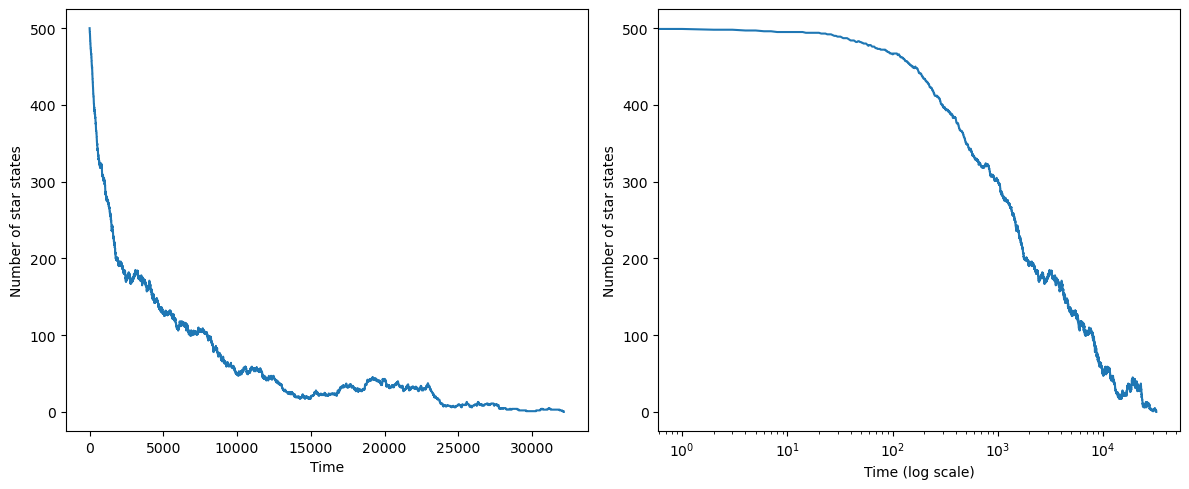

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

# Coalescence times

In [30]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [31]:
beta = 0.3
coup_type = 'gauss'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 3    
nb_itermax = 10**6
N_list = [100, 250, 500, 1000, 2500, 5000]
csv_path = f"../results/tmp/coal_time_ER_{coup_type}_d{d}.csv"

In [32]:
df = compute_coal_time(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, init_mode='full_star', lazy=False)

N=100
Coalescence achieved at iteration 6952 using full_star initialization.
Coalescence achieved at iteration 2893 using full_star initialization.
Coalescence achieved at iteration 6367 using full_star initialization.
N=250
Coalescence achieved at iteration 30379 using full_star initialization.
Coalescence achieved at iteration 7114 using full_star initialization.
Coalescence achieved at iteration 5967 using full_star initialization.
N=500
Coalescence achieved at iteration 34071 using full_star initialization.
Coalescence achieved at iteration 32843 using full_star initialization.
Coalescence achieved at iteration 66794 using full_star initialization.
N=1000
Coalescence achieved at iteration 78599 using full_star initialization.
Coalescence achieved at iteration 109398 using full_star initialization.
Coalescence achieved at iteration 170277 using full_star initialization.
N=2500
Coalescence achieved at iteration 239280 using full_star initialization.
Coalescence achieved at iteration 

In [33]:
if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [34]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['init_mode'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows

df

[0.3]
<StringArray>
['F_beta_Glauber']
Length: 1, dtype: str
[False]
<StringArray>
['full_star']
Length: 1, dtype: str
[3]
[1000000]
[ 100  250  500 1000 2500 5000]
6


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.3,F_beta_Glauber,False,full_star,3,1000000,100,3,5404.000000,1791.535096
1,0.3,F_beta_Glauber,False,full_star,3,1000000,250,3,14486.666667,11247.328463
2,0.3,F_beta_Glauber,False,full_star,3,1000000,500,3,44569.333333,15723.206889
3,0.3,F_beta_Glauber,False,full_star,3,1000000,1000,3,119424.666667,38092.995457
4,0.3,F_beta_Glauber,False,full_star,3,1000000,2500,3,318502.000000,58988.856191
5,0.3,F_beta_Glauber,False,full_star,3,1000000,5000,3,505070.000000,62210.417879


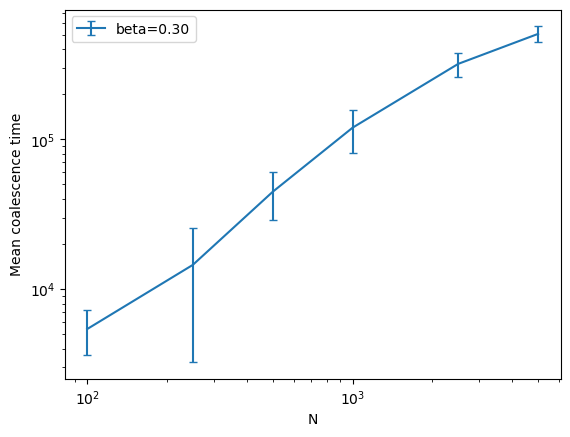

In [35]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') & 
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

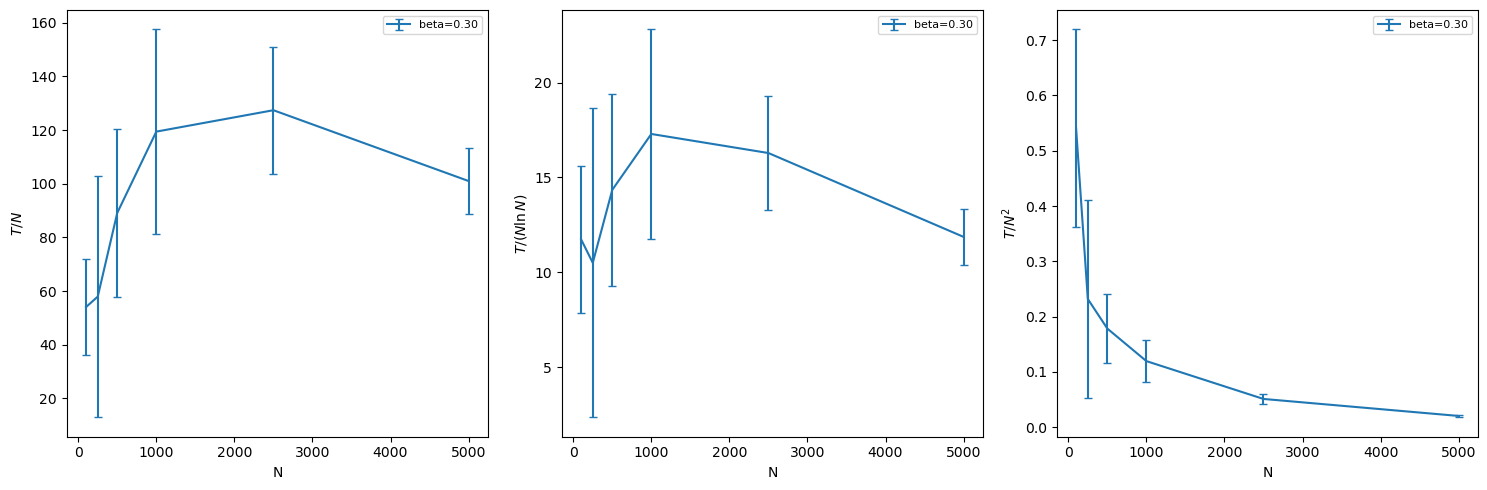

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

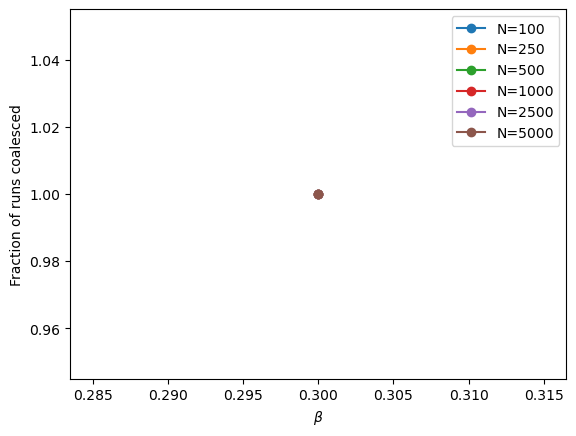

In [37]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star')
)
df_filtered = df[mask]
for N in df_filtered['N'].unique():
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    frac_converged = sub_df['n_coal'] / sub_df['n_runs']
    plt.plot(sub_df['beta'], frac_converged, 'o-', label=f'N={N}')

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

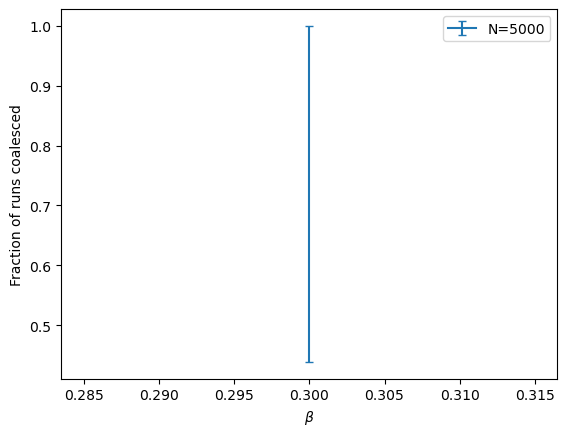

In [38]:
N_to_exclude = [100, 250, 500, 1000, 2500]
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()